In [1]:
# Import the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

from sklearn.model_selection import TimeSeriesSplit

In [2]:
# Load and sort the dataset

data_path = Path("../data/raw/load_data.csv")

df = pd.read_csv(data_path)

df["Date_Time"] = pd.to_datetime(
    df["Date_Time"],
    format="%d-%m-%Y %H:%M"
)

df = df.sort_values("Date_Time").reset_index(drop=True)

train_dev = df[
    df["Date_Time"] < "2018-12-01"
].copy()

test = df[
    df["Date_Time"] >= "2018-12-01"
].copy()

print("Development:", train_dev.shape)
print("Final test:", test.shape)

Development: (32064, 9)
Final test: (2977, 9)


In [4]:
def add_calendar_features(data):
    data = data.copy()

    data["Hour"] = data["Date_Time"].dt.hour
    data["Day_of_Week"] = data["Date_Time"].dt.day_of_week
    data["Month"] = data["Date_Time"].dt.month

    data["Time_Slot"] = (
        data["Date_Time"].dt.hour * 4
        + data["Date_Time"].dt.minute // 15
    )

    data["Is_Weekend"] = (
        data["Day_of_Week"] >= 5
    ).astype(int)

    return data


train_dev = add_calendar_features(train_dev)
test = add_calendar_features(test)

train_dev[
    ["Date_Time", "Hour", "Day_of_Week",
     "Month", "Time_Slot", "Is_Weekend"]
].head()

,Date_Time,Hour,Day_of_Week,Month,Time_Slot,Is_Weekend
0,2018-01-01 00:00:00,0,0,1,0,0
1,2018-01-01 00:15:00,0,0,1,1,0
2,2018-01-01 00:30:00,0,0,1,2,0
3,2018-01-01 00:45:00,0,0,1,3,0
4,2018-01-01 01:00:00,1,0,1,4,0


In [5]:
# Split training and validation

validation_start = pd.Timestamp("2018-10-01")

train = train_dev[
    train_dev["Date_Time"] < validation_start
].copy()

val = train_dev[
    train_dev["Date_Time"] >= validation_start
].copy()

print("Training records:", len(train))
print("Validation records:", len(val))

print("\nTraining period:")
print(train["Date_Time"].min(), train["Date_Time"].max())

print("\nValidation period:")
print(val["Date_Time"].min(), val["Date_Time"].max())

Training records: 26208
Validation records: 5856

Training period:
2018-01-01 00:00:00 2018-09-30 23:45:00

Validation period:
2018-10-01 00:00:00 2018-11-30 23:45:00


In [6]:
# Define features

calendar_features = [
    "Hour",
    "Day_of_Week",
    "Month",
    "Time_Slot",
    "Is_Weekend"
]

X_train = train[calendar_features]
y_train = train["Load_Type"]

X_val = val[calendar_features]
y_val = val["Load_Type"]

In [7]:
# Train Dummy Classifier

dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_val)

print("Accuracy:",
      round(accuracy_score(y_val, dummy_predictions), 4))

print("Macro F1:",
      round(f1_score(
          y_val,
          dummy_predictions,
          average="macro",
          zero_division=0
      ), 4))

print("\nClassification Report:")
print(classification_report(
    y_val,
    dummy_predictions,
    zero_division=0
))

Accuracy: 0.4836
Macro F1: 0.2173

Classification Report:
              precision    recall  f1-score   support

  Light_Load       0.48      1.00      0.65      2832
Maximum_Load       0.00      0.00      0.00      1296
 Medium_Load       0.00      0.00      0.00      1728

    accuracy                           0.48      5856
   macro avg       0.16      0.33      0.22      5856
weighted avg       0.23      0.48      0.32      5856



In [8]:
# Train a Decision Tree


tree_model = DecisionTreeClassifier(
    max_depth=8,
    min_samples_leaf=20,
    random_state=42
)

tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_val)

print("Accuracy:",
      round(accuracy_score(y_val, tree_predictions), 4))

print("Macro F1:",
      round(f1_score(
          y_val,
          tree_predictions,
          average="macro",
          zero_division=0
      ), 4))

print("\nClassification Report:")
print(classification_report(
    y_val,
    tree_predictions,
    zero_division=0
))

Accuracy: 0.8347
Macro F1: 0.7898

Classification Report:
              precision    recall  f1-score   support

  Light_Load       0.96      0.98      0.97      2832
Maximum_Load       0.67      0.65      0.66      1296
 Medium_Load       0.75      0.73      0.74      1728

    accuracy                           0.83      5856
   macro avg       0.79      0.79      0.79      5856
weighted avg       0.83      0.83      0.83      5856



In [12]:
# Compare both models
results = pd.DataFrame({
    "Model": ["Dummy Classifier", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_val, dummy_predictions),
        accuracy_score(y_val, tree_predictions)
    ],
    "Macro F1": [
        f1_score(y_val, dummy_predictions, average="macro"),
        f1_score(y_val, tree_predictions, average="macro")
    ]
})

results.round(4)


,Model,Accuracy,Macro F1
0,Dummy Classifier,0.4836,0.2173
1,Decision Tree,0.8347,0.7898


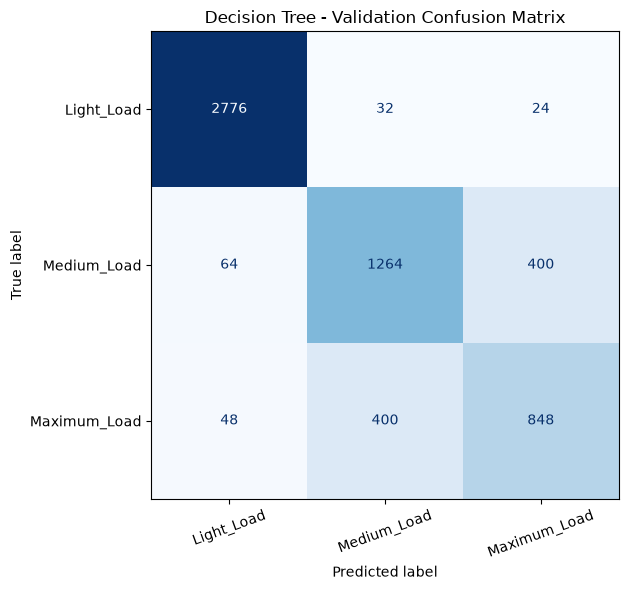

In [13]:
# Plot the confusion matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_labels = [
    "Light_Load",
    "Medium_Load",
    "Maximum_Load"
]

cm = confusion_matrix(
    y_val,
    tree_predictions,
    labels=class_labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Decision Tree - Validation Confusion Matrix")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [14]:
# Train a Random forest

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_val)

print("Accuracy:", round(
    accuracy_score(y_val, rf_predictions), 4
))

print("Macro F1:", round(
    f1_score(y_val, rf_predictions, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(
    y_val,
    rf_predictions,
    zero_division=0
))

Accuracy: 0.8347
Macro F1: 0.7898

Classification Report:
              precision    recall  f1-score   support

  Light_Load       0.96      0.98      0.97      2832
Maximum_Load       0.67      0.65      0.66      1296
 Medium_Load       0.75      0.73      0.74      1728

    accuracy                           0.83      5856
   macro avg       0.79      0.79      0.79      5856
weighted avg       0.83      0.83      0.83      5856



In [16]:
model_predictions = {
    "Dummy Classifier": dummy_predictions,
    "Decision Tree": tree_predictions,
    "Random Forest": rf_predictions
}

comparison = []

for name, predictions in model_predictions.items():
    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(
            y_val,
            predictions,
            average="macro",
            zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison)

comparison_df.sort_values(
    "Macro F1",
    ascending=False
).round(4)


,Model,Accuracy,Macro F1
1,Decision Tree,0.8347,0.7898
2,Random Forest,0.8347,0.7898
0,Dummy Classifier,0.4836,0.2173


In [17]:
# Compare predictions

same_predictions = np.mean(
    tree_predictions == rf_predictions
)

print(
    "Prediction agreement:",
    round(same_predictions * 100, 2), "%"
)

print(
    "Different predictions:",
    np.sum(tree_predictions != rf_predictions)
)

Prediction agreement: 100.0 %
Different predictions: 0


In [18]:
# Define combined features

telemetry_features = [
    "Usage_kWh",
    "Lagging_Current_Reactive.Power_kVarh",
    "Leading_Current_Reactive_Power_kVarh",
    "CO2(tCO2)",
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor"
]

combined_features = calendar_features + telemetry_features

X_train_combined = train[combined_features].copy()
X_val_combined = val[combined_features].copy()

In [19]:
# Build a preprocessing pipeline

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

class PowerFactorCleaner(BaseEstimator, TransformerMixin):
    def __init__(self, columns):
        self.columns = columns

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        for col in self.columns:
            X.loc[
                (X[col] < 0) | (X[col] > 100),
                col
            ] = np.nan

        return X


power_factor_columns = [
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor"
]

combined_rf = Pipeline([
    (
        "power_factor_cleaner",
        PowerFactorCleaner(power_factor_columns)
    ),
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=200,
            max_depth=12,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )
    )
])

In [20]:
# Train the combined model


combined_rf.fit(
    X_train_combined,
    y_train
)

combined_predictions = combined_rf.predict(
    X_val_combined
)

print(
    "Accuracy:",
    round(
        accuracy_score(y_val, combined_predictions),
        4
    )
)

print(
    "Macro F1:",
    round(
        f1_score(
            y_val,
            combined_predictions,
            average="macro",
            zero_division=0
        ),
        4
    )
)

print("\nClassification Report:")

print(
    classification_report(
        y_val,
        combined_predictions,
        zero_division=0
    )
)

Accuracy: 0.8373
Macro F1: 0.7925

Classification Report:
              precision    recall  f1-score   support

  Light_Load       0.99      0.98      0.98      2832
Maximum_Load       0.66      0.67      0.66      1296
 Medium_Load       0.73      0.74      0.73      1728

    accuracy                           0.84      5856
   macro avg       0.79      0.79      0.79      5856
weighted avg       0.84      0.84      0.84      5856



In [22]:
comparison = pd.DataFrame([
    {
        "Model": "Calendar-only Random Forest",
        "Accuracy": accuracy_score(y_val, rf_predictions),
        "Macro F1": f1_score(
            y_val, rf_predictions, average="macro"
        )
    },
    {
        "Model": "Calendar + Telemetry Random Forest",
        "Accuracy": accuracy_score(y_val, combined_predictions),
        "Macro F1": f1_score(
            y_val, combined_predictions, average="macro"
        )
    }
])

comparison.round(4)

,Model,Accuracy,Macro F1
0,Calendar-only Random Forest,0.8347,0.7898
1,Calendar + Telemetry Random Forest,0.8373,0.7925


In [23]:
# Define monthly validation folds

validation_months = [
    "2018-07",
    "2018-08",
    "2018-09",
    "2018-10",
    "2018-11"
]

folds = []

for month in validation_months:
    start = pd.Period(month).start_time
    end = (pd.Period(month) + 1).start_time

    train_mask = train_dev["Date_Time"] < start
    val_mask = (
        (train_dev["Date_Time"] >= start)
        & (train_dev["Date_Time"] < end)
    )

    folds.append((
        month,
        train_dev.loc[train_mask],
        train_dev.loc[val_mask]
    ))

for month, fold_train, fold_val in folds:
    print(
        month,
        "Training:", len(fold_train),
        "Validation:", len(fold_val)
    )

2018-07 Training: 17376 Validation: 2976
2018-08 Training: 20352 Validation: 2976
2018-09 Training: 23328 Validation: 2880
2018-10 Training: 26208 Validation: 2976
2018-11 Training: 29184 Validation: 2880


In [25]:
from sklearn.base import clone

cv_results = []

models = {
    "Calendar RF": rf_model,
    "Combined RF": combined_rf
}

feature_sets = {
    "Calendar RF": calendar_features,
    "Combined RF": combined_features
}

for month, fold_train, fold_val in folds:

    for name, model in models.items():

        features = feature_sets[name]

        X_fold_train = fold_train[features]
        y_fold_train = fold_train["Load_Type"]

        X_fold_val = fold_val[features]
        y_fold_val = fold_val["Load_Type"]

        estimator = clone(model)

        estimator.fit(X_fold_train, y_fold_train)

        predictions = estimator.predict(X_fold_val)

        cv_results.append({
            "Month": month,
            "Model": name,
            "Accuracy": accuracy_score(
                y_fold_val, predictions
            ),
            "Macro_F1": f1_score(
                y_fold_val,
                predictions,
                average="macro",
                zero_division=0
            )
        })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df.round(4)

,Month,Model,Accuracy,Macro_F1
0,2018-07,Calendar RF,0.9435,0.9441
1,2018-07,Combined RF,0.9647,0.9657
2,2018-08,Calendar RF,0.8495,0.8502
3,2018-08,Combined RF,0.9281,0.9302
4,2018-09,Calendar RF,0.8833,0.8802
5,2018-09,Combined RF,0.9323,0.9316
6,2018-10,Calendar RF,1.0000,1.0000
7,2018-10,Combined RF,0.9879,0.9877
8,2018-11,Calendar RF,0.6639,0.5753
9,2018-11,Combined RF,0.6809,0.5932


In [27]:
cv_summary = (
    cv_results_df
    .groupby("Model")
    .agg(
        Mean_Accuracy=("Accuracy", "mean"),
        Std_Accuracy=("Accuracy", "std"),
        Mean_Macro_F1=("Macro_F1", "mean"),
        Std_Macro_F1=("Macro_F1", "std")
    )
    .sort_values("Mean_Macro_F1", ascending=False)
)

cv_summary.round(4)

,Mean_Accuracy,Std_Accuracy,Mean_Macro_F1,Std_Macro_F1
Model,,,,
Combined RF,0.8988,0.1242,0.8817,0.1631
Calendar RF,0.8680,0.1278,0.8500,0.1641


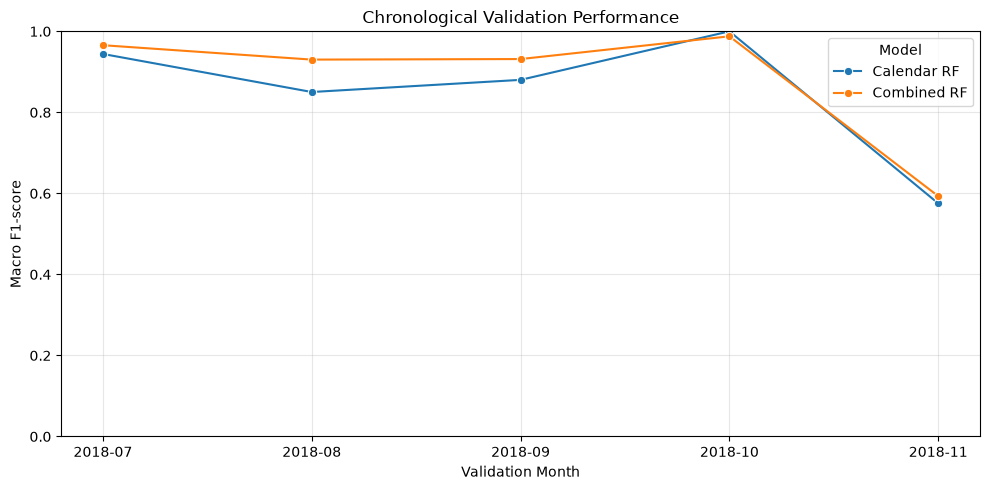

In [28]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=cv_results_df,
    x="Month",
    y="Macro_F1",
    hue="Model",
    marker="o"
)

plt.title("Chronological Validation Performance")
plt.xlabel("Validation Month")
plt.ylabel("Macro F1-score")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
# Train and evaluate on November

nov_train = train_dev[
    train_dev["Date_Time"] < "2018-11-01"
].copy()

nov_val = train_dev[
    (train_dev["Date_Time"] >= "2018-11-01")
    & (train_dev["Date_Time"] < "2018-12-01")
].copy()

nov_model = clone(combined_rf)

nov_model.fit(
    nov_train[combined_features],
    nov_train["Load_Type"]
)

nov_predictions = nov_model.predict(
    nov_val[combined_features]
)

print(classification_report(
    nov_val["Load_Type"],
    nov_predictions,
    zero_division=0
))

              precision    recall  f1-score   support

  Light_Load       0.96      0.98      0.97      1368
Maximum_Load       0.33      0.33      0.33       648
 Medium_Load       0.49      0.47      0.48       864

    accuracy                           0.68      2880
   macro avg       0.59      0.59      0.59      2880
weighted avg       0.68      0.68      0.68      2880



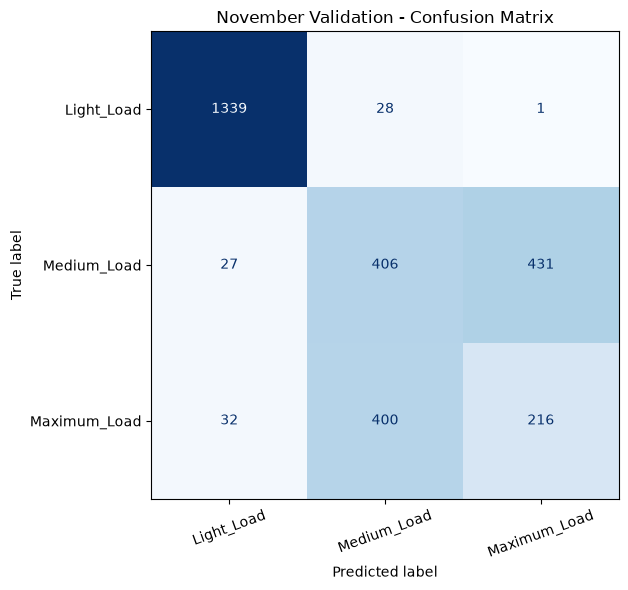

In [30]:
nov_cm = confusion_matrix(
    nov_val["Load_Type"],
    nov_predictions,
    labels=class_labels
)

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay(
    confusion_matrix=nov_cm,
    display_labels=class_labels
).plot(
    ax=ax,
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

plt.title("November Validation - Confusion Matrix")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [32]:
nov_analysis = nov_val[
    ["Date_Time", "Load_Type"]
].copy()

nov_analysis["Prediction"] = nov_predictions

nov_analysis["Week"] = (
    nov_analysis["Date_Time"].dt.day.sub(1) // 7 + 1
)

weekly_results = []

for week, group in nov_analysis.groupby("Week"):
    weekly_results.append({
        "Week": week,
        "Records": len(group),
        "Accuracy": accuracy_score(
            group["Load_Type"],
            group["Prediction"]
        ),
        "Macro_F1": f1_score(
            group["Load_Type"],
            group["Prediction"],
            labels=class_labels,
            average="macro",
            zero_division=0
        )
    })

weekly_results_df = pd.DataFrame(weekly_results)

weekly_results_df.round(4)

,Week,Records,Accuracy,Macro_F1
0,1,672,0.6488,0.5871
1,2,672,0.7113,0.6076
2,3,672,0.6488,0.5871
3,4,672,0.7188,0.5844
4,5,192,0.6667,0.6111


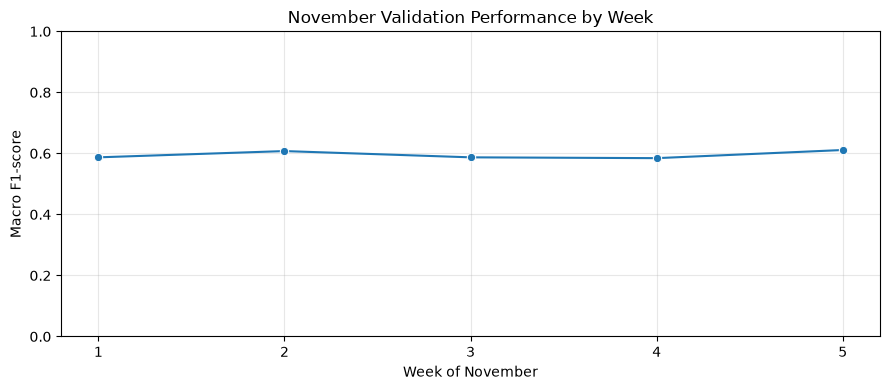

In [33]:
plt.figure(figsize=(9, 4))

sns.lineplot(
    data=weekly_results_df,
    x="Week",
    y="Macro_F1",
    marker="o"
)

plt.title("November Validation Performance by Week")
plt.xlabel("Week of November")
plt.ylabel("Macro F1-score")
plt.ylim(0, 1)
plt.xticks(weekly_results_df["Week"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
# Compare models with and without Month

features_without_month = [
    col for col in combined_features
    if col != "Month"
]

month_ablation_results = []

for month, fold_train, fold_val in folds:

    for label, features in [
        ("With Month", combined_features),
        ("Without Month", features_without_month)
    ]:
        model = clone(combined_rf)

        model.fit(
            fold_train[features],
            fold_train["Load_Type"]
        )

        predictions = model.predict(
            fold_val[features]
        )

        month_ablation_results.append({
            "Month": month,
            "Feature_Set": label,
            "Macro_F1": f1_score(
                fold_val["Load_Type"],
                predictions,
                average="macro",
                zero_division=0
            )
        })

month_ablation_df = pd.DataFrame(month_ablation_results)

month_ablation_df.pivot(
        index="Month",
        columns="Feature_Set",
        values="Macro_F1"
    ).round(4)

Feature_Set,With Month,Without Month
Month,,
2018-07,0.9657,0.9399
2018-08,0.9302,0.9341
2018-09,0.9316,0.9245
2018-10,0.9877,0.9886
2018-11,0.5932,0.6021


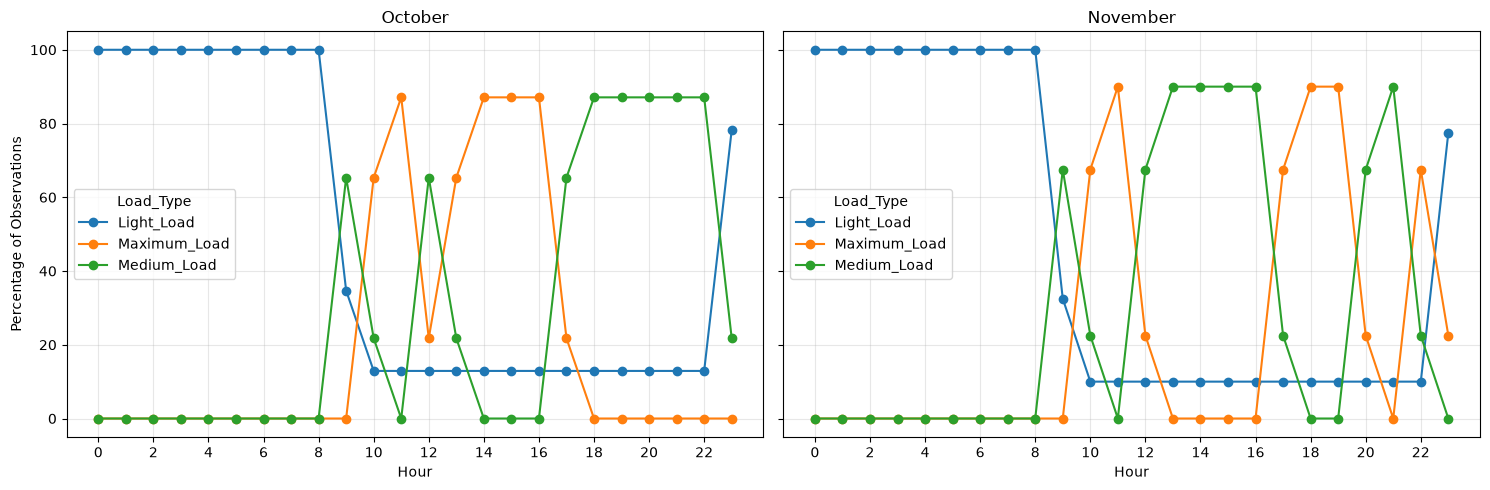

In [36]:
# Compare October and November hourly distributions

schedule_df = train_dev.copy()

schedule_df["Hour"] = schedule_df["Date_Time"].dt.hour
schedule_df["Month_Num"] = schedule_df["Date_Time"].dt.month

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for ax, month in zip(axes, [10, 11]):

    subset = schedule_df[
        schedule_df["Month_Num"] == month
    ]

    hourly = pd.crosstab(
        subset["Hour"],
        subset["Load_Type"],
        normalize="index"
    ) * 100

    hourly.plot(
        kind="line",
        marker="o",
        ax=ax
    )

    ax.set_title(
        "October" if month == 10 else "November"
    )
    ax.set_xlabel("Hour")
    ax.set_ylabel("Percentage of Observations")
    ax.set_xticks(range(0, 24, 2))
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [38]:
# Compare the dominant weekday schedule

schedule_df["Day_of_Week"] = (
    schedule_df["Date_Time"].dt.day_of_week
)

schedule_df["Time_Slot"] = (
    schedule_df["Date_Time"].dt.hour * 4
    + schedule_df["Date_Time"].dt.minute // 15
)

def get_dominant_schedule(data, month):
    subset = data[
        data["Month_Num"] == month
    ]

    return (
        subset.groupby(
            ["Day_of_Week", "Time_Slot"]
        )["Load_Type"]
        .agg(lambda x: x.mode().iloc[0])
    )

oct_schedule = get_dominant_schedule(schedule_df, 10)
nov_schedule = get_dominant_schedule(schedule_df, 11)

schedule_comparison = pd.DataFrame({
    "October": oct_schedule,
    "November": nov_schedule
}).dropna()

schedule_comparison["Changed"] = (
    schedule_comparison["October"]
    != schedule_comparison["November"]
)

print(
    "Changed schedule slots:",
    schedule_comparison["Changed"].sum()
)

print(
    "Total compared slots:",
    len(schedule_comparison)
)

print(
    "Percentage changed:",
    round(
        schedule_comparison["Changed"].mean() * 100,
        2
    )
)


schedule_comparison[
        schedule_comparison["Changed"]
    ].head(20)


Changed schedule slots: 192
Total compared slots: 672
Percentage changed: 28.57


October      November  Changed
Day_of_Week Time_Slot                                     
0           53         Maximum_Load   Medium_Load     True
            54         Maximum_Load   Medium_Load     True
            55         Maximum_Load   Medium_Load     True
            56         Maximum_Load   Medium_Load     True
            57         Maximum_Load   Medium_Load     True
            58         Maximum_Load   Medium_Load     True
            59         Maximum_Load   Medium_Load     True
            60         Maximum_Load   Medium_Load     True
            61         Maximum_Load   Medium_Load     True
            62         Maximum_Load   Medium_Load     True
            63         Maximum_Load   Medium_Load     True
            64         Maximum_Load   Medium_Load     True
            65         Maximum_Load   Medium_Load     True
            66         Maximum_Load   Medium_Load     True
            67         Maximum_Load   Medium_Load     True
            68         Maximum_Load   Medium_Load     True
            69          Medium_Load  Maximum_Load     True
            70          Medium_Load  Maximum_Load     True
            71          Medium_Load  Maximum_Load     True
            72          Medium_Load  Maximum_Load     True

In [39]:
# Monthly dominant load schedule

schedule_df = train_dev.copy()

schedule_df["Month_Num"] = schedule_df["Date_Time"].dt.month
schedule_df["Day_of_Week"] = schedule_df["Date_Time"].dt.day_of_week
schedule_df["Time_Slot"] = (
    schedule_df["Date_Time"].dt.hour * 4
    + schedule_df["Date_Time"].dt.minute // 15
)

monthly_schedules = {}

for month in sorted(schedule_df["Month_Num"].unique()):
    subset = schedule_df[
        schedule_df["Month_Num"] == month
    ]

    dominant = (
        subset.groupby(
            ["Day_of_Week", "Time_Slot"]
        )["Load_Type"]
        .agg(lambda x: x.mode().iloc[0])
    )

    monthly_schedules[month] = dominant

In [41]:
# Compare monthly schedules

months = sorted(monthly_schedules)

similarity_matrix = pd.DataFrame(
    index=months,
    columns=months,
    dtype=float
)

for m1 in months:
    for m2 in months:
        comparison = pd.concat(
            [
                monthly_schedules[m1],
                monthly_schedules[m2]
            ],
            axis=1,
            join="inner"
        )

        similarity_matrix.loc[m1, m2] = (
            comparison.iloc[:, 0]
            == comparison.iloc[:, 1]
        ).mean()

similarity_matrix.round(3)

,1,2,3,4,5,6,7,8,9,10,11
1,1.000,0.917,0.714,0.714,0.714,0.714,0.631,0.679,0.714,0.714,1.000
2,0.917,1.000,0.679,0.679,0.679,0.679,0.595,0.762,0.679,0.679,0.917
3,0.714,0.679,1.000,1.000,1.000,1.000,0.917,0.917,1.000,1.000,0.714
4,0.714,0.679,1.000,1.000,1.000,1.000,0.917,0.917,1.000,1.000,0.714
5,0.714,0.679,1.000,1.000,1.000,1.000,0.917,0.917,1.000,1.000,0.714
6,0.714,0.679,1.000,1.000,1.000,1.000,0.917,0.917,1.000,1.000,0.714
7,0.631,0.595,0.917,0.917,0.917,0.917,1.000,0.833,0.917,0.917,0.631
8,0.679,0.762,0.917,0.917,0.917,0.917,0.833,1.000,0.917,0.917,0.679
9,0.714,0.679,1.000,1.000,1.000,1.000,0.917,0.917,1.000,1.000,0.714
10,0.714,0.679,1.000,1.000,1.000,1.000,0.917,0.917,1.000,1.000,0.714


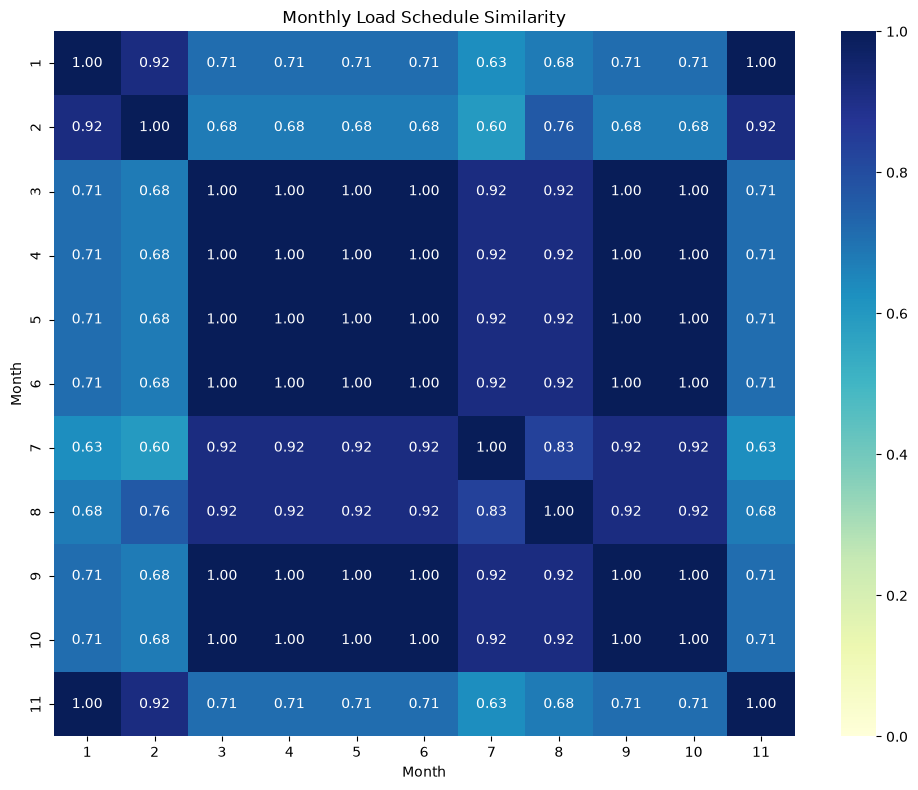

In [42]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    similarity_matrix.astype(float),
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1
)

plt.title("Monthly Load Schedule Similarity")
plt.xlabel("Month")
plt.ylabel("Month")
plt.tight_layout()
plt.show()

In [43]:
# Build  a January schedule lookup

jan_data = train_dev[
    train_dev["Date_Time"].dt.month == 1
].copy()

jan_schedule = (
    jan_data.groupby(
        ["Day_of_Week", "Time_Slot"]
    )["Load_Type"]
    .agg(lambda x: x.mode().iloc[0])
)

print("January schedule slots:", len(jan_schedule))

January schedule slots: 672


In [44]:
# Apply January schedule to November

nov_data = train_dev[
    train_dev["Date_Time"].dt.month == 11
].copy()

nov_keys = pd.MultiIndex.from_frame(
    nov_data[["Day_of_Week", "Time_Slot"]]
)

jan_schedule_predictions = jan_schedule.reindex(
    nov_keys
).to_numpy()

print(
    "Missing predictions:",
    pd.isna(jan_schedule_predictions).sum()
)

print(
    "Accuracy:",
    round(
        accuracy_score(
            nov_data["Load_Type"],
            jan_schedule_predictions
        ),
        4
    )
)

print(
    "Macro F1:",
    round(
        f1_score(
            nov_data["Load_Type"],
            jan_schedule_predictions,
            average="macro",
            zero_division=0
        ),
        4
    )
)

Missing predictions: 0
Accuracy: 0.9417
Macro F1: 0.9422


In [45]:
# Compare January lookup against November Random Forest

diagnostic_comparison = pd.DataFrame([
    {
        "Model": "Combined Random Forest",
        "Accuracy": accuracy_score(
            nov_data["Load_Type"],
            nov_predictions
        ),
        "Macro_F1": f1_score(
            nov_data["Load_Type"],
            nov_predictions,
            average="macro",
            zero_division=0
        )
    },
    {
        "Model": "January Schedule Lookup",
        "Accuracy": accuracy_score(
            nov_data["Load_Type"],
            jan_schedule_predictions
        ),
        "Macro_F1": f1_score(
            nov_data["Load_Type"],
            jan_schedule_predictions,
            average="macro",
            zero_division=0
        )
    }
])

diagnostic_comparison.round(4)

,Model,Accuracy,Macro_F1
0,Combined Random Forest,0.6809,0.5932
1,January Schedule Lookup,0.9417,0.9422


In [46]:
# Define a schedule lookup classifier

from sklearn.base import BaseEstimator, ClassifierMixin

class ScheduleLookupClassifier(BaseEstimator, ClassifierMixin):

    def fit(self, X, y):
        data = X[["Day_of_Week", "Time_Slot"]].copy()
        data["Target"] = np.asarray(y)

        self.lookup_ = (
            data.groupby(["Day_of_Week", "Time_Slot"])["Target"]
            .agg(lambda values: values.value_counts().idxmax())
        )

        self.default_class_ = data["Target"].mode().iloc[0]

        return self

    def predict(self, X):
        keys = pd.MultiIndex.from_frame(
            X[["Day_of_Week", "Time_Slot"]]
        )

        predictions = self.lookup_.reindex(keys)

        return predictions.fillna(
            self.default_class_
        ).to_numpy()

In [48]:
# Evaluate using expanding-window validation

lookup_results = []

for month, fold_train, fold_val in folds:

    model = ScheduleLookupClassifier()

    model.fit(
        fold_train[["Day_of_Week", "Time_Slot"]],
        fold_train["Load_Type"]
    )

    predictions = model.predict(
        fold_val[["Day_of_Week", "Time_Slot"]]
    )

    lookup_results.append({
        "Month": month,
        "Accuracy": accuracy_score(
            fold_val["Load_Type"],
            predictions
        ),
        "Macro_F1": f1_score(
            fold_val["Load_Type"],
            predictions,
            average="macro",
            zero_division=0
        )
    })

lookup_results_df = pd.DataFrame(lookup_results)

lookup_results_df.round(4)

,Month,Accuracy,Macro_F1
0,2018-07,0.9435,0.9441
1,2018-08,0.8871,0.8845
2,2018-09,0.8833,0.8802
3,2018-10,1.0000,1.0000
4,2018-11,0.6639,0.5753


In [51]:
# Compare lookup and Random Forest

rf_comparison = cv_results_df[
    cv_results_df["Model"] == "Combined RF"
][["Month", "Accuracy", "Macro_F1"]].copy()

rf_comparison["Model"] = "Combined RF"

lookup_comparison = lookup_results_df.copy()
lookup_comparison["Model"] = "Schedule Lookup"

all_results = pd.concat(
    [rf_comparison, lookup_comparison],
    ignore_index=True
)

all_results.pivot(
        index="Month",
        columns="Model",
        values="Macro_F1"
    ).round(4)


all_results.groupby("Model")[
        ["Accuracy", "Macro_F1"]
    ].mean().round(4)

,Accuracy,Macro_F1
Model,,
Combined RF,0.8988,0.8817
Schedule Lookup,0.8756,0.8568


In [52]:
# Identify unique monthly schedules

schedule_signatures = {}

for month, schedule in monthly_schedules.items():
    signature = tuple(
        schedule.sort_index().to_numpy()
    )

    schedule_signatures[month] = signature

unique_patterns = {}

for month, signature in schedule_signatures.items():
    matched = False

    for pattern_id, months in unique_patterns.items():
        reference_month = months[0]

        if signature == schedule_signatures[reference_month]:
            months.append(month)
            matched = True
            break

    if not matched:
        pattern_id = len(unique_patterns) + 1
        unique_patterns[pattern_id] = [month]

for pattern_id, months in unique_patterns.items():
    print(f"Pattern {pattern_id}: {months}")



Pattern 1: [np.int32(1), np.int32(11)]
Pattern 2: [np.int32(2)]
Pattern 3: [np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(9), np.int32(10)]
Pattern 4: [np.int32(7)]
Pattern 5: [np.int32(8)]


In [53]:
# Quantify differences between January and October

jan_schedule = monthly_schedules[1]
oct_schedule = monthly_schedules[10]

comparison = pd.DataFrame({
    "January": jan_schedule,
    "October": oct_schedule
})

comparison["Different"] = (
    comparison["January"] != comparison["October"]
)

print(
    "Different time slots:",
    comparison["Different"].sum()
)

print(
    "Percentage different:",
    round(comparison["Different"].mean() * 100, 2)
)

comparison[comparison["Different"]].head(20)


Different time slots: 192
Percentage different: 28.57


January       October  Different
Day_of_Week Time_Slot                                       
0           53          Medium_Load  Maximum_Load       True
            54          Medium_Load  Maximum_Load       True
            55          Medium_Load  Maximum_Load       True
            56          Medium_Load  Maximum_Load       True
            57          Medium_Load  Maximum_Load       True
            58          Medium_Load  Maximum_Load       True
            59          Medium_Load  Maximum_Load       True
            60          Medium_Load  Maximum_Load       True
            61          Medium_Load  Maximum_Load       True
            62          Medium_Load  Maximum_Load       True
            63          Medium_Load  Maximum_Load       True
            64          Medium_Load  Maximum_Load       True
            65          Medium_Load  Maximum_Load       True
            66          Medium_Load  Maximum_Load       True
            67          Medium_Load  Maximum_Load       True
            68          Medium_Load  Maximum_Load       True
            69         Maximum_Load   Medium_Load       True
            70         Maximum_Load   Medium_Load       True
            71         Maximum_Load   Medium_Load       True
            72         Maximum_Load   Medium_Load       True

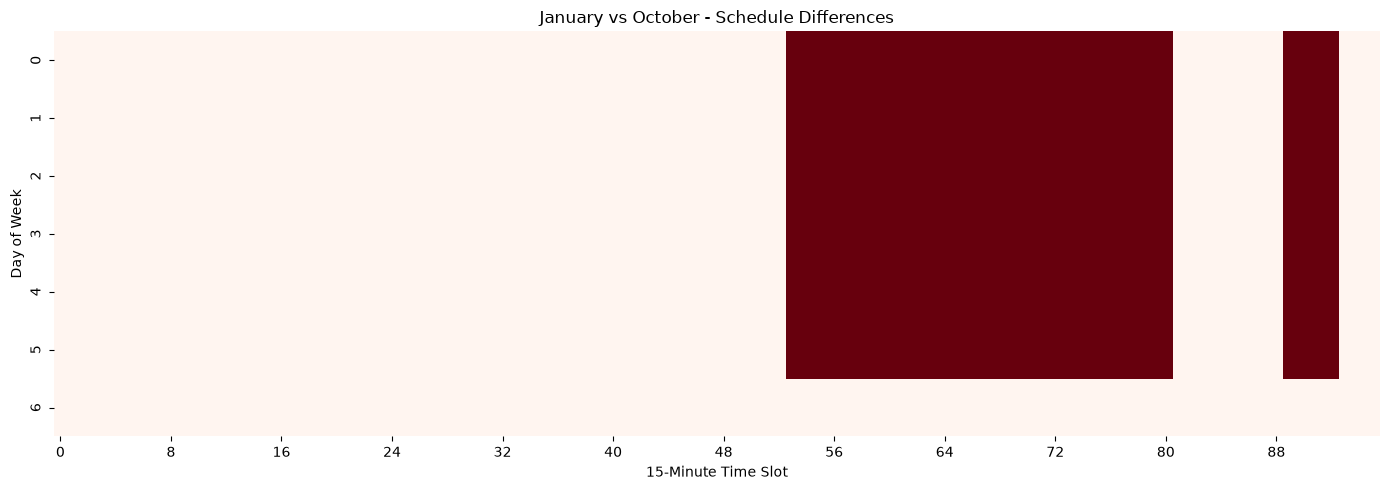

In [54]:
# Examine where the schedules differ

difference_matrix = (
    comparison["Different"]
    .unstack("Time_Slot")
    .astype(int)
)

plt.figure(figsize=(14, 5))

sns.heatmap(
    difference_matrix,
    cmap="Reds",
    cbar=False,
    xticklabels=8
)

plt.title("January vs October - Schedule Differences")
plt.xlabel("15-Minute Time Slot")
plt.ylabel("Day of Week")
plt.tight_layout()
plt.show()


In [55]:
# Define a seasonal grouping 

def add_schedule_regime(data):
    data = data.copy()

    month = data["Date_Time"].dt.month

    data["Schedule_Regime"] = np.where(
        month.isin([1, 2, 11, 12]),
        0,
        1
    )

    return data

In [56]:
# Add regime features

regime_dev = add_schedule_regime(train_dev)

regime_features = [
    "Schedule_Regime",
    "Day_of_Week",
    "Time_Slot"
]

regime_dev[
        ["Date_Time"] + regime_features
    ].head()


,Date_Time,Schedule_Regime,Day_of_Week,Time_Slot
0,2018-01-01 00:00:00,0,0,0
1,2018-01-01 00:15:00,0,0,1
2,2018-01-01 00:30:00,0,0,2
3,2018-01-01 00:45:00,0,0,3
4,2018-01-01 01:00:00,0,0,4


In [57]:
# Implement a regime-aware lookup

class RegimeScheduleLookup(BaseEstimator, ClassifierMixin):

    def fit(self, X, y):
        data = X[
            ["Schedule_Regime", "Day_of_Week", "Time_Slot"]
        ].copy()

        data["Target"] = np.asarray(y)

        self.lookup_ = (
            data.groupby(
                ["Schedule_Regime", "Day_of_Week", "Time_Slot"]
            )["Target"]
            .agg(lambda x: x.value_counts().idxmax())
        )

        self.default_class_ = data["Target"].mode().iloc[0]

        return self

    def predict(self, X):
        keys = pd.MultiIndex.from_frame(
            X[
                ["Schedule_Regime", "Day_of_Week", "Time_Slot"]
            ]
        )

        predictions = self.lookup_.reindex(keys)

        return predictions.fillna(
            self.default_class_
        ).to_numpy()

In [62]:
# Evaluate chronological folds

regime_results = []

for month, fold_train, fold_val in folds:

    fold_train = add_schedule_regime(fold_train)
    fold_val = add_schedule_regime(fold_val)

    model = RegimeScheduleLookup()

    model.fit(
        fold_train[regime_features],
        fold_train["Load_Type"]
    )

    predictions = model.predict(
        fold_val[regime_features]
    )

    regime_results.append({
        "Month": month,
        "Accuracy": accuracy_score(
            fold_val["Load_Type"],
            predictions
        ),
        "Macro_F1": f1_score(
            fold_val["Load_Type"],
            predictions,
            average="macro",
            zero_division=0
        )
    })

regime_results_df = pd.DataFrame(regime_results)

regime_results_df.round(4)

,Month,Accuracy,Macro_F1
0,2018-07,0.9435,0.9441
1,2018-08,0.8871,0.8845
2,2018-09,0.8833,0.8802
3,2018-10,1.0000,1.0000
4,2018-11,0.9417,0.9422


In [63]:
# Compare three approaches

regime_comparison = regime_results_df.copy()
regime_comparison["Model"] = "Regime Lookup"

global_comparison = lookup_results_df.copy()
global_comparison["Model"] = "Global Lookup"

rf_comparison = cv_results_df[
    cv_results_df["Model"] == "Combined RF"
].copy()

comparison = pd.concat(
    [
        regime_comparison,
        global_comparison,
        rf_comparison
    ],
    ignore_index=True
)


comparison.pivot(
        index="Month",
        columns="Model",
        values="Macro_F1"
    ).round(4)


comparison.groupby("Model")[
        ["Accuracy", "Macro_F1"]
    ].mean().round(4)


,Accuracy,Macro_F1
Model,,
Combined RF,0.8988,0.8817
Global Lookup,0.8756,0.8568
Regime Lookup,0.9311,0.9302


In [61]:
# Improve the fallback strategy

class RegimeScheduleLookup(BaseEstimator, ClassifierMixin):

    def fit(self, X, y):
        data = X[
            ["Schedule_Regime", "Day_of_Week", "Time_Slot"]
        ].copy()

        data["Target"] = np.asarray(y)

        self.regime_lookup_ = (
            data.groupby(
                ["Schedule_Regime", "Day_of_Week", "Time_Slot"]
            )["Target"]
            .agg(lambda x: x.value_counts().idxmax())
        )

        self.global_lookup_ = (
            data.groupby(
                ["Day_of_Week", "Time_Slot"]
            )["Target"]
            .agg(lambda x: x.value_counts().idxmax())
        )

        self.default_class_ = data["Target"].mode().iloc[0]

        return self

    def predict(self, X):
        regime_keys = pd.MultiIndex.from_frame(
            X[["Schedule_Regime", "Day_of_Week", "Time_Slot"]]
        )

        slot_keys = pd.MultiIndex.from_frame(
            X[["Day_of_Week", "Time_Slot"]]
        )

        predictions = pd.Series(
            self.regime_lookup_.reindex(regime_keys).to_numpy(),
            index=X.index
        )

        fallback = pd.Series(
            self.global_lookup_.reindex(slot_keys).to_numpy(),
            index=X.index
        )

        return (
            predictions
            .fillna(fallback)
            .fillna(self.default_class_)
            .to_numpy()
        )


In [64]:
# Robust Regime Schedule Lookup

from sklearn.base import BaseEstimator, ClassifierMixin
import numpy as np
import pandas as pd

class RegimeScheduleLookup(BaseEstimator, ClassifierMixin):

    def fit(self, X, y):
        required = [
            "Schedule_Regime",
            "Day_of_Week",
            "Time_Slot"
        ]

        data = X[required].reset_index(drop=True).copy()
        data["Target"] = np.asarray(y)

        self.regime_lookup_ = (
            data.groupby(required)["Target"]
            .agg(lambda s: s.value_counts().idxmax())
        )

        self.global_lookup_ = (
            data.groupby(["Day_of_Week", "Time_Slot"])["Target"]
            .agg(lambda s: s.value_counts().idxmax())
        )

        self.default_class_ = data["Target"].mode().iloc[0]
        self.classes_ = np.unique(data["Target"])

        return self

    def predict(self, X):
        regime_keys = pd.MultiIndex.from_frame(
            X[[
                "Schedule_Regime",
                "Day_of_Week",
                "Time_Slot"
            ]]
        )

        global_keys = pd.MultiIndex.from_frame(
            X[["Day_of_Week", "Time_Slot"]]
        )

        regime_predictions = self.regime_lookup_.reindex(
            regime_keys
        ).to_numpy()

        global_predictions = self.global_lookup_.reindex(
            global_keys
        ).to_numpy()

        predictions = pd.Series(regime_predictions)

        predictions = predictions.fillna(
            pd.Series(global_predictions)
        ).fillna(self.default_class_)

        return predictions.to_numpy()

In [66]:
# Chronological validation

final_lookup_results = []

for month, fold_train, fold_val in folds:

    fold_train = add_schedule_regime(fold_train)
    fold_val = add_schedule_regime(fold_val)

    model = RegimeScheduleLookup()

    model.fit(
        fold_train[regime_features],
        fold_train["Load_Type"]
    )

    predictions = model.predict(
        fold_val[regime_features]
    )

    final_lookup_results.append({
        "Month": month,
        "Accuracy": accuracy_score(
            fold_val["Load_Type"],
            predictions
        ),
        "Macro_F1": f1_score(
            fold_val["Load_Type"],
            predictions,
            average="macro",
            zero_division=0
        )
    })

final_lookup_results_df = pd.DataFrame(
    final_lookup_results
)

final_lookup_results_df.round(4)

,Month,Accuracy,Macro_F1
0,2018-07,0.9435,0.9441
1,2018-08,0.8871,0.8845
2,2018-09,0.8833,0.8802
3,2018-10,1.0000,1.0000
4,2018-11,0.9417,0.9422


In [67]:
# Final development comparison


rf_summary = cv_results_df[
    cv_results_df["Model"] == "Combined RF"
][["Month", "Accuracy", "Macro_F1"]].copy()

rf_summary["Model"] = "Combined RF"

lookup_summary = final_lookup_results_df.copy()
lookup_summary["Model"] = "Regime Lookup (Exploratory)"

final_comparison = pd.concat(
    [rf_summary, lookup_summary],
    ignore_index=True
)

final_comparison.groupby("Model").agg(
        Mean_Accuracy=("Accuracy", "mean"),
        Mean_Macro_F1=("Macro_F1", "mean"),
        Std_Macro_F1=("Macro_F1", "std")
    ).round(4)



,Mean_Accuracy,Mean_Macro_F1,Std_Macro_F1
Model,,,
Combined RF,0.8988,0.8817,0.1631
Regime Lookup (Exploratory),0.9311,0.9302,0.0495


In [70]:
# Recreate the December holdout from the original dataset

final_test = df.loc[
    df["Date_Time"] >= pd.Timestamp("2018-12-01")
].copy()

# Apply the same calendar features used during training
final_test = add_calendar_features(final_test)

print("Final test shape:", final_test.shape)

print("\nDate range:")
print(final_test["Date_Time"].min())
print(final_test["Date_Time"].max())

print("\nTarget column present:",
      "Load_Type" in final_test.columns)

if "Load_Type" in final_test.columns:
    print("\nMissing target values:")
    print(final_test["Load_Type"].isna().sum())

print("\nChronological separation:")
print(
    train_dev["Date_Time"].max()
    < final_test["Date_Time"].min()
)

print("\nMissing model features:")
print(
    set(combined_features) - set(final_test.columns)
)

Final test shape: (2977, 14)

Date range:
2018-12-01 00:00:00
2018-12-31 23:45:00

Target column present: True

Missing target values:
0

Chronological separation:
True

Missing model features:
set()


In [71]:
# Fit the final Random Forest

from sklearn.base import clone

final_model = clone(combined_rf)

X_development = train_dev[combined_features].copy()
y_development = train_dev["Load_Type"].copy()

final_model.fit(
    X_development,
    y_development
)

print("Final model trained successfully.")
print("Training records:", len(X_development))
print("Features:", len(combined_features))
print("Classes:", final_model.classes_)

Final model trained successfully.
Training records: 32064
Features: 11
Classes: ['Light_Load' 'Maximum_Load' 'Medium_Load']


In [72]:
# Inspect the final holdout

print("Final test shape:", final_test.shape)

print("\nDate range:")
print(final_test["Date_Time"].min())
print(final_test["Date_Time"].max())

print("\nTarget column present:",
      "Load_Type" in final_test.columns)

if "Load_Type" in final_test.columns:
    print("\nMissing target values:")
    print(final_test["Load_Type"].isna().sum())

print("\nChronological separation:")
print(
    train_dev["Date_Time"].max()
    < final_test["Date_Time"].min()
)

Final test shape: (2977, 14)

Date range:
2018-12-01 00:00:00
2018-12-31 23:45:00

Target column present: True

Missing target values:
0

Chronological separation:
True


In [73]:
# Inspect the duplicate

duplicate_rows = final_test[
    final_test.duplicated(
        subset="Date_Time",
        keep=False
    )
].sort_values("Date_Time")
duplicate_rows.T

,35024,35025
Date_Time,2018-12-31 20:00:00,2018-12-31 20:00:00
Usage_kWh,NaN,4.14
Lagging_Current_Reactive.Power_kVarh,0.0,0.0
Leading_Current_Reactive_Power_kVarh,20.1,20.09
CO2(tCO2),0.0,0.0
Lagging_Current_Power_Factor,217.27347,100.0
Leading_Current_Power_Factor,20.19,20.18
NSM,72000.0,72000.0
Load_Type,Light_Load,Light_Load
Hour,20,20


In [74]:
# Resolve the duplicate

# Create a temporary copy for quality assessment
test_quality = final_test.copy()

pf_columns = [
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor"
]

# Count missing measurements
test_quality["Quality_Issues"] = (
    test_quality[combined_features]
    .isna()
    .sum(axis=1)
)

# Count invalid power factors
for col in pf_columns:
    test_quality["Quality_Issues"] += (
        (test_quality[col] < 0) |
        (test_quality[col] > 100)
    ).astype(int)

# Prefer records with fewer quality issues
test_quality = test_quality.sort_values(
    ["Date_Time", "Quality_Issues"],
    kind="stable"
)

final_test_clean = (
    test_quality
    .drop_duplicates(subset="Date_Time", keep="first")
    .drop(columns="Quality_Issues")
    .sort_values("Date_Time")
    .reset_index(drop=True)
)

print("Before:", len(final_test))
print("After:", len(final_test_clean))
print(
    "Remaining duplicate timestamps:",
    final_test_clean["Date_Time"].duplicated().sum()
)

Before: 2977
After: 2976
Remaining duplicate timestamps: 0


In [75]:
# Sanity checks

assert len(final_test_clean) == 2976

assert final_test_clean["Date_Time"].is_unique

assert (
    train_dev["Date_Time"].max()
    < final_test_clean["Date_Time"].min()
)

assert final_test_clean["Load_Type"].notna().all()

assert set(combined_features).issubset(
    final_test_clean.columns
)

print("All final test checks passed.")

All final test checks passed.


In [76]:
# Evaluate the frozen Random Forest

X_test = final_test_clean[combined_features]
y_test = final_test_clean["Load_Type"]

test_predictions = final_model.predict(X_test)

print("Predictions generated:", len(test_predictions))

Predictions generated: 2976


In [78]:
# Final evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

final_metrics = {
    "Accuracy": accuracy_score(
        y_test, test_predictions
    ),
    "Macro Precision": precision_score(
        y_test, test_predictions,
        average="macro",
        zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, test_predictions,
        average="macro",
        zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, test_predictions,
        average="macro",
        zero_division=0
    )
}


pd.DataFrame(
        final_metrics.items(),
        columns=["Metric", "Score"]
    ).round(4)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        test_predictions,
        zero_division=0
    )
)


Classification Report:
              precision    recall  f1-score   support

  Light_Load       0.98      0.91      0.94      1744
Maximum_Load       0.90      0.76      0.82       528
 Medium_Load       0.73      0.95      0.82       704

    accuracy                           0.89      2976
   macro avg       0.87      0.87      0.86      2976
weighted avg       0.91      0.89      0.89      2976



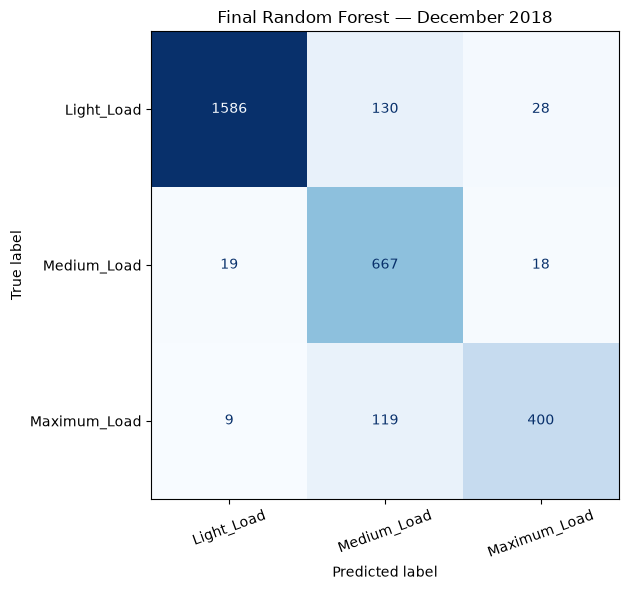

In [79]:
# Final confusion matrix

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix
)

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=class_labels
)

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Final Random Forest — December 2018")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [80]:
# Create output directories

from pathlib import Path

PROJECT_ROOT = Path.cwd()

MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

print("Models directory:", MODELS_DIR)
print("Results directory:", RESULTS_DIR)

Models directory: c:\Users\Asus\OneDrive\Desktop\Power System Load Classification\notebook\models
Results directory: c:\Users\Asus\OneDrive\Desktop\Power System Load Classification\notebook\results


In [81]:
# Save the trained pipeline

import joblib

model_path = MODELS_DIR / "final_random_forest.joblib"

joblib.dump(final_model, model_path)

print("Model saved:", model_path)

Model saved: c:\Users\Asus\OneDrive\Desktop\Power System Load Classification\notebook\models\final_random_forest.joblib


In [82]:
# Export final evaluation metrics

import json

metrics_to_save = {
    "model": "Combined Random Forest",
    "test_period": "December 2018",
    "test_samples": len(y_test),
    "accuracy": float(final_metrics["Accuracy"]),
    "macro_precision": float(final_metrics["Macro Precision"]),
    "macro_recall": float(final_metrics["Macro Recall"]),
    "macro_f1": float(final_metrics["Macro F1"])
}

metrics_path = RESULTS_DIR / "final_metrics.json"

with open(metrics_path, "w") as f:
    json.dump(metrics_to_save, f, indent=4)

print("Metrics saved:", metrics_path)

Metrics saved: c:\Users\Asus\OneDrive\Desktop\Power System Load Classification\notebook\results\final_metrics.json


In [84]:
# Export predictions

predictions_df = pd.DataFrame({
    "Date_Time": final_test_clean["Date_Time"],
    "Actual_Load_Type": y_test,
    "Predicted_Load_Type": test_predictions
})

predictions_df["Correct"] = (
    predictions_df["Actual_Load_Type"]
    == predictions_df["Predicted_Load_Type"]
)

predictions_path = RESULTS_DIR / "final_predictions.csv"

predictions_df.to_csv(predictions_path, index=False)

print("Predictions saved:", predictions_path)
print("Total predictions:", len(predictions_df))

predictions_df.head(10)

Predictions saved: c:\Users\Asus\OneDrive\Desktop\Power System Load Classification\notebook\results\final_predictions.csv
Total predictions: 2976


,Date_Time,Actual_Load_Type,Predicted_Load_Type,Correct
0,2018-12-01 00:00:00,Light_Load,Light_Load,True
1,2018-12-01 00:15:00,Light_Load,Light_Load,True
2,2018-12-01 00:30:00,Light_Load,Light_Load,True
3,2018-12-01 00:45:00,Light_Load,Light_Load,True
4,2018-12-01 01:00:00,Light_Load,Light_Load,True
5,2018-12-01 01:15:00,Light_Load,Light_Load,True
6,2018-12-01 01:30:00,Light_Load,Light_Load,True
7,2018-12-01 01:45:00,Light_Load,Light_Load,True
8,2018-12-01 02:00:00,Light_Load,Light_Load,True
9,2018-12-01 02:15:00,Light_Load,Light_Load,True


In [85]:
# Reload the model from disk
loaded_model = joblib.load(model_path)

# Generate predictions using the reloaded model
reloaded_predictions = loaded_model.predict(
    final_test_clean[combined_features]
)

# Compare against the original predictions
predictions_match = np.array_equal(
    test_predictions,
    reloaded_predictions
)

print("Model reload successful.")
print("Predictions identical:", predictions_match)
print("Total predictions:", len(reloaded_predictions))

assert predictions_match, "Reloaded model predictions differ!"

Model reload successful.
Predictions identical: True
Total predictions: 2976


In [87]:
feature_metadata = {
    "model_name": "Combined Random Forest",
    "target": "Load_Type",
    "features": list(combined_features),
    "classes": loaded_model.classes_.tolist(),
    "training_period": "January–November 2018",
    "test_period": "December 2018"
}

metadata_path = MODELS_DIR / "model_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(feature_metadata, f, indent=4)

print("Metadata saved successfully.")

pd.DataFrame({
    "Feature": combined_features
})

Metadata saved successfully.


,Feature
0,Hour
1,Day_of_Week
2,Month
3,Time_Slot
4,Is_Weekend
5,Usage_kWh
6,Lagging_Current_Reactive.Power_kVarh
7,Leading_Current_Reactive_Power_kVarh
8,CO2(tCO2)
9,Lagging_Current_Power_Factor


In [88]:
print("Model type:")
print(type(loaded_model))

print("\nPipeline steps:")
if hasattr(loaded_model, "named_steps"):
    for name, step in loaded_model.named_steps.items():
        print(f"{name}: {type(step).__name__}")
else:
    print("The saved object is not a sklearn Pipeline.")

print("\nFeature names:")
print(combined_features)

print("\nLibrary versions:")
import sklearn
import pandas
import numpy

print("scikit-learn:", sklearn.__version__)
print("pandas:", pandas.__version__)
print("numpy:", numpy.__version__)
print("joblib:", joblib.__version__)

Model type:
<class 'sklearn.pipeline.Pipeline'>

Pipeline steps:
power_factor_cleaner: PowerFactorCleaner
imputer: SimpleImputer
classifier: RandomForestClassifier

Feature names:
['Hour', 'Day_of_Week', 'Month', 'Time_Slot', 'Is_Weekend', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor']

Library versions:
scikit-learn: 1.9.1
pandas: 3.1.0
numpy: 2.5.4
joblib: 1.6.0


In [89]:
for directory in [MODELS_DIR, RESULTS_DIR]:
    print(f"\n{directory.name}/")

    for file in sorted(directory.iterdir()):
        if file.is_file():
            print(
                f"  {file.name} "
                f"({file.stat().st_size / 1024:.1f} KB)"
            )


models/
  final_random_forest.joblib (12705.2 KB)
  model_metadata.json (0.6 KB)

results/
  final_metrics.json (0.3 KB)
  final_predictions.csv (143.4 KB)


In [90]:
import inspect

print(inspect.getsource(PowerFactorCleaner))

OSError: source code not available

In [91]:
from pathlib import Path

# Search all notebooks in the current directory and subdirectories
notebooks = list(Path.cwd().rglob("*.ipynb"))

print("Notebooks found:", len(notebooks))

import json

for notebook_path in notebooks:
    with open(notebook_path, encoding="utf-8") as f:
        notebook = json.load(f)

    for i, cell in enumerate(notebook.get("cells", [])):
        source = "".join(cell.get("source", []))

        if "class PowerFactorCleaner" in source:
            print("\nNotebook:", notebook_path)
            print("Cell index:", i)
            print("\nClass definition cell:\n")
            print(source)

Notebooks found: 2

Notebook: c:\Users\Asus\OneDrive\Desktop\Power System Load Classification\notebook\feature_engineering_modeling.ipynb
Cell index: 13

Class definition cell:

# Build a preprocessing pipeline

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

class PowerFactorCleaner(BaseEstimator, TransformerMixin):
    def __init__(self, columns):
        self.columns = columns

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        for col in self.columns:
            X.loc[
                (X[col] < 0) | (X[col] > 100),
                col
            ] = np.nan

        return X


power_factor_columns = [
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor"
]

combined_rf = Pipeline([
    (
        "power_factor_cleaner",
        PowerFactorCleaner(power_factor_columns)
    ),
    (
        "imputer",
        SimpleImputer

In [92]:
import json
from pathlib import Path

notebook_path = Path("feature_engineering_modeling.ipynb")

with open(notebook_path, encoding="utf-8") as f:
    notebook = json.load(f)

source = "".join(notebook["cells"][13]["source"])

start = source.index("class PowerFactorCleaner")
end = source.index("\n# ", start) if "\n# " in source[start:] else len(source)

print(source[start:end])

class PowerFactorCleaner(BaseEstimator, TransformerMixin):
    def __init__(self, columns):
        self.columns = columns

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        for col in self.columns:
            X.loc[
                (X[col] < 0) | (X[col] > 100),
                col
            ] = np.nan

        return X


power_factor_columns = [
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor"
]

combined_rf = Pipeline([
    (
        "power_factor_cleaner",
        PowerFactorCleaner(power_factor_columns)
    ),
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=200,
            max_depth=12,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )
    )
])
